In [1]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.feature_selection import RFECV
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import shap

# Aesthetics
sns.set_theme(style="whitegrid", font_scale=1.05)
plt.rcParams['font.sans-serif'] = 'Arial'

print("Required modeling, SHAP, and visualization libraries imported successfully.")


Required modeling, SHAP, and visualization libraries imported successfully.


In [2]:
df = pd.read_csv("womens_clothing_regression_dataset.csv")
print(f"Dataset shape: {df.shape}")

candidate_features = [
    'Length_of_Membership',
    'Time_on_App',
    'Avg_Session_Length',
    'Time_on_Website',
    'Annual_Orders',
    'Avg_Order_Value',
    'Age',
    'Rating',
    'Recommended IND',
    'Positive Feedback Count'
]
target = 'Yearly_Amount_Spent'

X = df[candidate_features]
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
print(f"Training observations: {X_train.shape[0]}, Test observations: {X_test.shape[0]}")


Dataset shape: (23465, 20)
Training observations: 18772, Test observations: 4693


In [3]:
dt_model = DecisionTreeRegressor(max_depth=6, min_samples_split=20, min_samples_leaf=10, random_state=42)
dt_model.fit(X_train, y_train)
y_pred_dt = dt_model.predict(X_test)

rf_model = RandomForestRegressor(n_estimators=100, max_depth=12, min_samples_split=10, min_samples_leaf=5, n_jobs=-1, random_state=42)
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)

scaler = StandardScaler()
X_tr_sc = scaler.fit_transform(X_train)
X_te_sc = scaler.transform(X_test)
lr_model = LinearRegression().fit(X_tr_sc, y_train)
y_pred_lr = lr_model.predict(X_te_sc)

perf_df = pd.DataFrame([
    {
        'Algorithm': 'Decision Tree Regressor (Depth=6)',
        'Test R² Score': round(r2_score(y_test, y_pred_dt), 4),
        'Test RMSE ($)': round(np.sqrt(mean_squared_error(y_test, y_pred_dt)), 2),
        'Test MAE ($)': round(mean_absolute_error(y_test, y_pred_dt), 2)
    },
    {
        'Algorithm': 'Random Forest Regressor (100 Trees)',
        'Test R² Score': round(r2_score(y_test, y_pred_rf), 4),
        'Test RMSE ($)': round(np.sqrt(mean_squared_error(y_test, y_pred_rf)), 2),
        'Test MAE ($)': round(mean_absolute_error(y_test, y_pred_rf), 2)
    },
    {
        'Algorithm': 'Standardized Linear Regression',
        'Test R² Score': round(r2_score(y_test, y_pred_lr), 4),
        'Test RMSE ($)': round(np.sqrt(mean_squared_error(y_test, y_pred_lr)), 2),
        'Test MAE ($)': round(mean_absolute_error(y_test, y_pred_lr), 2)
    }
])
perf_df


,Algorithm,Test R² Score,Test RMSE ($),Test MAE ($)
0,Decision Tree Regressor (Depth=6),0.8637,54.20,43.21
1,Random Forest Regressor (100 Trees),0.9509,32.52,25.63
2,Standardized Linear Regression,0.9643,27.74,22.05


In [4]:
comp_df = pd.read_csv("cross_model_feature_importance_comparison.csv")
comp_df


,Feature,DT_MDI_Importance,RF_MDI_Importance,Permutation_Importance,Linear_Reg_Std_Coef,DT_Rank,RF_Rank,Perm_Rank,LR_Rank,Consensus_Mean_Rank
0,Length_of_Membership,0.7775,0.7151,0.6921,0.3226,1,1,1,1,1.00
1,Time_on_App,0.0815,0.0947,0.1103,0.1676,2,2,2,3,2.25
2,Avg_Order_Value,0.0715,0.0817,0.1103,0.1712,3,3,2,2,2.50
3,Annual_Orders,0.0683,0.0710,0.0569,0.1590,4,4,4,4,4.00
4,Avg_Session_Length,0.0012,0.0269,0.0261,0.0968,5,5,5,5,5.00
5,Age,0.0000,0.0069,0.0044,0.0779,6,6,6,6,6.00
6,Rating,0.0000,0.0006,0.0000,0.0017,6,9,7,7,7.25
7,Positive Feedback Count,0.0000,0.0009,0.0000,0.0013,6,8,7,8,7.25
8,Recommended IND,0.0000,0.0001,-0.0000,0.0010,6,10,7,9,8.00
9,Time_on_Website,0.0000,0.0022,-0.0001,0.0009,6,7,10,10,8.25


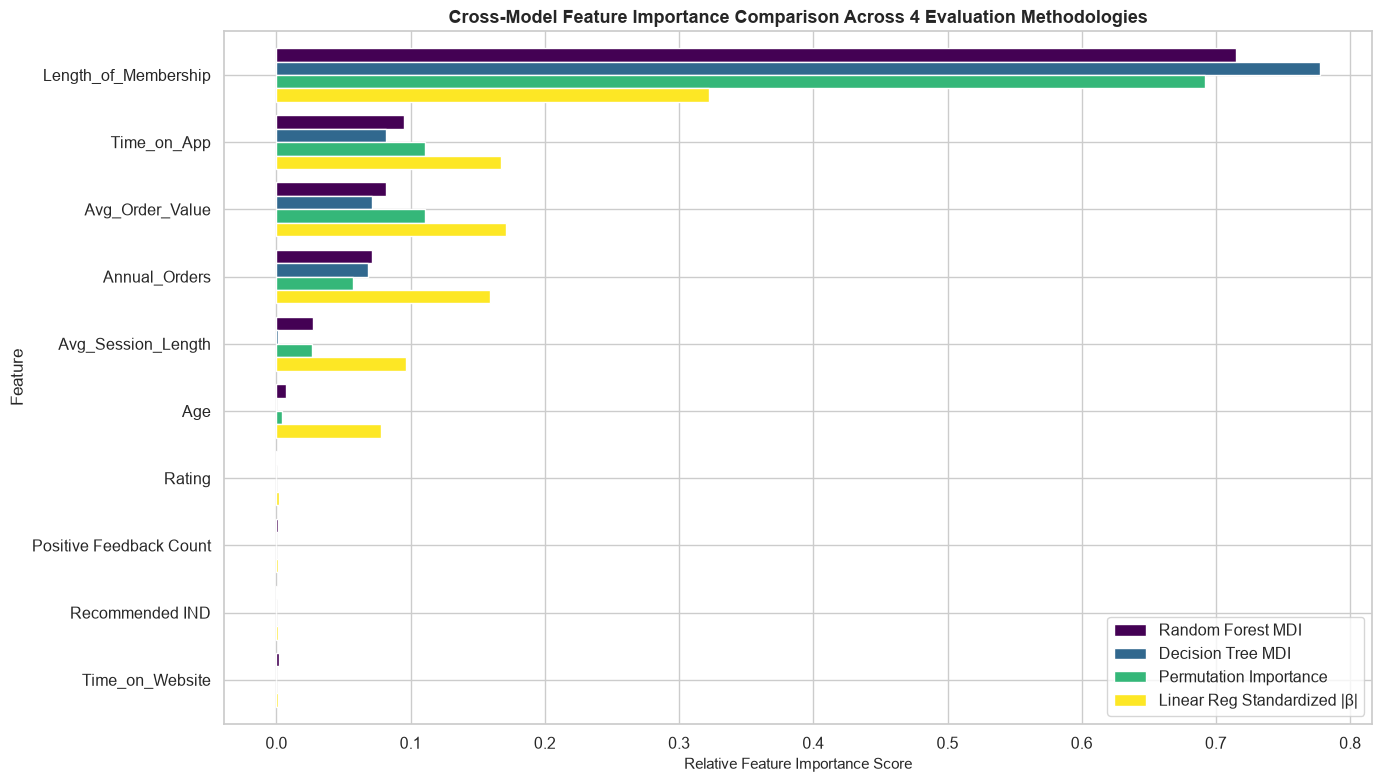

In [5]:
fig, ax = plt.subplots(figsize=(14, 8))
comp_plot_df = comp_df.set_index('Feature')[['RF_MDI_Importance', 'DT_MDI_Importance', 'Permutation_Importance', 'Linear_Reg_Std_Coef']]
comp_plot_df.columns = ['Random Forest MDI', 'Decision Tree MDI', 'Permutation Importance', 'Linear Reg Standardized |β|']
comp_plot_df.plot(kind='barh', ax=ax, width=0.8, colormap='viridis')
ax.set_title("Cross-Model Feature Importance Comparison Across 4 Evaluation Methodologies", fontweight='bold', fontsize=13)
ax.set_xlabel("Relative Feature Importance Score", fontsize=11)
ax.invert_yaxis()
plt.tight_layout()
plt.savefig("feature_importance_cross_model_comparison.png", dpi=300)
plt.show()


In [6]:
# Global SHAP importance ranking table
shap_rank_df = pd.read_csv("shap_global_feature_importance.csv")
shap_rank_df


,Feature,Mean_Absolute_SHAP_Impact,SHAP_Rank
0,Length_of_Membership,89.1164,1
1,Avg_Order_Value,34.0844,2
2,Time_on_App,33.5368,3
3,Annual_Orders,22.3261,4
4,Avg_Session_Length,15.7861,5
5,Age,3.5439,6
6,Rating,0.3194,7
7,Time_on_Website,0.3097,8
8,Positive Feedback Count,0.1328,9
9,Recommended IND,0.1151,10


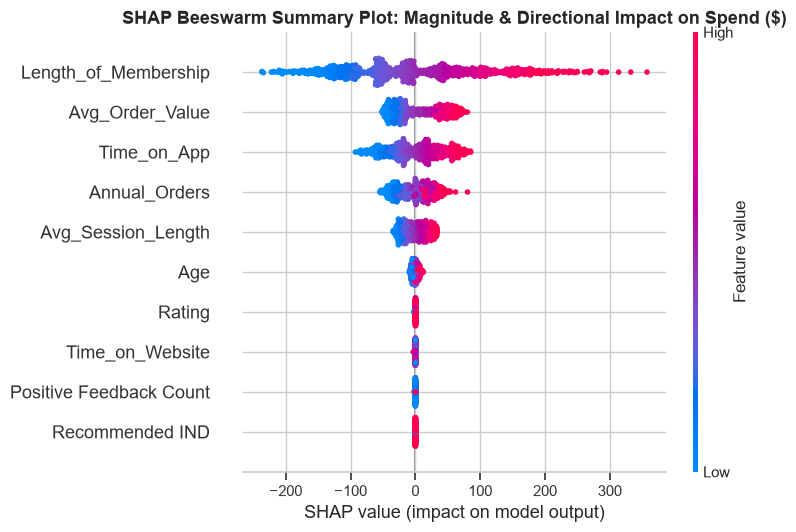

In [7]:
# Load TreeExplainer and compute SHAP values for sample
explainer = shap.TreeExplainer(rf_model)
X_shap_sample = X_test.sample(n=1000, random_state=42)
shap_values = explainer(X_shap_sample)

# Figure 1: Beeswarm summary plot
fig, ax = plt.subplots(figsize=(12, 7))
shap.plots.beeswarm(shap_values, max_display=10, show=False)
plt.title("SHAP Beeswarm Summary Plot: Magnitude & Directional Impact on Spend ($)", fontweight='bold', fontsize=13)
plt.tight_layout()
plt.savefig("shap_beeswarm_summary.png", dpi=300)
plt.show()


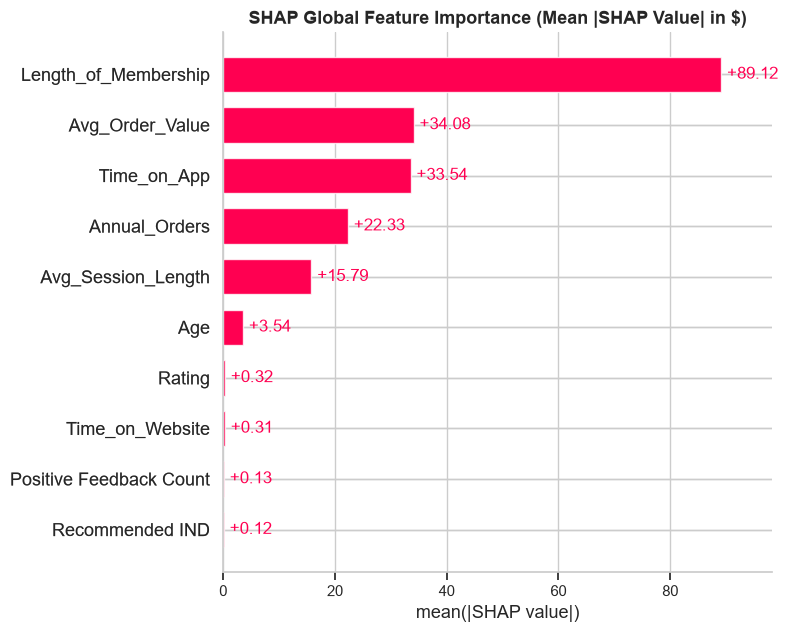

In [8]:
# Figure 2: Mean Absolute Bar Plot
fig, ax = plt.subplots(figsize=(11, 6))
shap.plots.bar(shap_values, max_display=10, show=False)
plt.title("SHAP Global Feature Importance (Mean |SHAP Value| in $)", fontweight='bold', fontsize=13)
plt.tight_layout()
plt.savefig("shap_bar_importance.png", dpi=300)
plt.show()


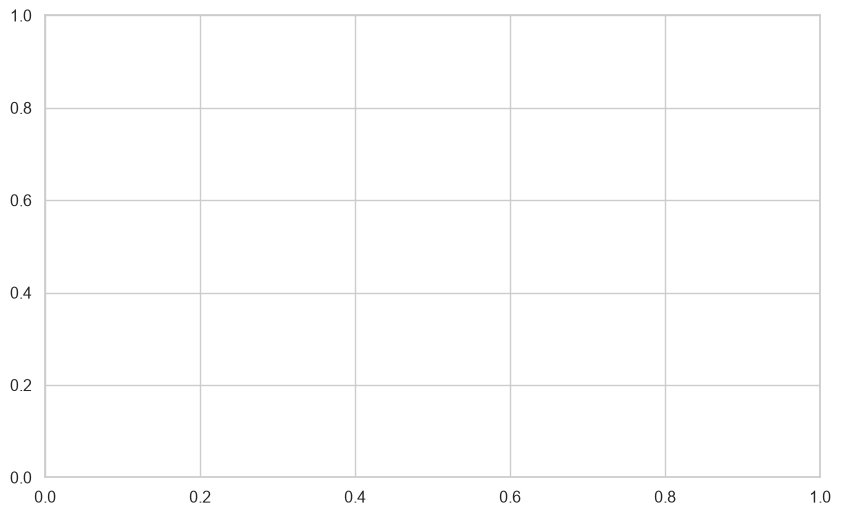

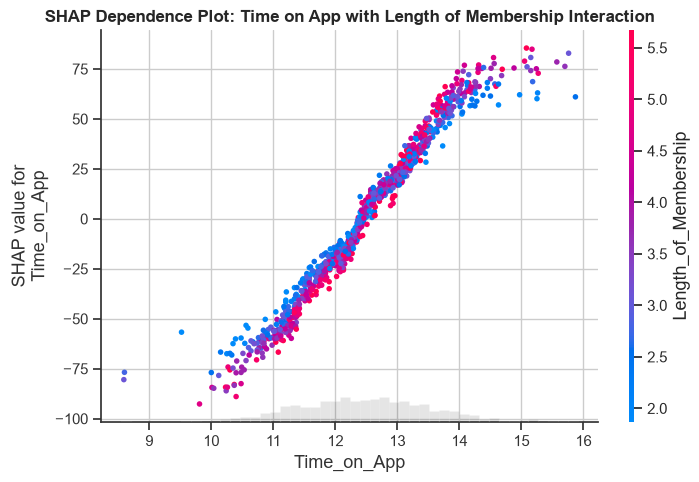

In [9]:
# Figure 3: SHAP Dependence Plot for Time_on_App interacting with Length_of_Membership
fig, ax = plt.subplots(figsize=(10, 6))
shap.plots.scatter(shap_values[:, "Time_on_App"], color=shap_values[:, "Length_of_Membership"], show=False)
plt.title("SHAP Dependence Plot: Time on App with Length of Membership Interaction", fontweight='bold', fontsize=12)
plt.tight_layout()
plt.savefig("shap_dependence_app_membership.png", dpi=300)
plt.show()


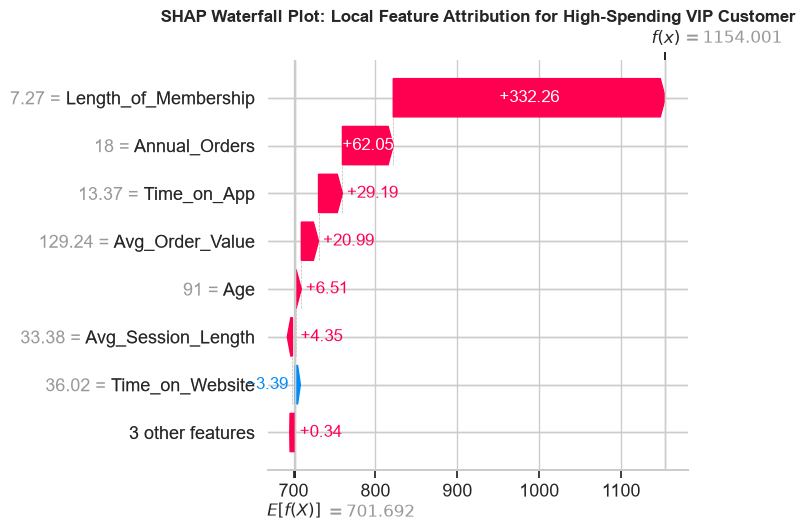

In [10]:
# Figure 4: Local Waterfall Explanation for VIP Customer
high_spend_idx = int(np.argmax(shap_values.values.sum(axis=1)))
fig, ax = plt.subplots(figsize=(10, 7))
shap.plots.waterfall(shap_values[high_spend_idx], max_display=8, show=False)
plt.title("SHAP Waterfall Plot: Local Feature Attribution for High-Spending VIP Customer", fontweight='bold', fontsize=12)
plt.tight_layout()
plt.savefig("shap_waterfall_local_explanation.png", dpi=300)
plt.show()


In [11]:
df_traj = pd.read_csv("rfecv_feature_selection_trajectory.csv")
print("RFECV Selection Trajectory Across Feature Counts:")
df_traj


RFECV Selection Trajectory Across Feature Counts:


,Number_of_Features,Mean_CV_R2,Std_CV_R2,Optimal_Selection
0,1,0.7070,0.0072,No
1,2,0.8139,0.0048,No
2,3,0.8960,0.0042,No
3,4,0.9248,0.0026,No
4,5,0.9432,0.0021,No
5,6,0.9444,0.0021,YES (Optimal)
6,7,0.9439,0.0021,No
7,8,0.9436,0.0021,No
8,9,0.9435,0.0021,No
9,10,0.9435,0.0021,No


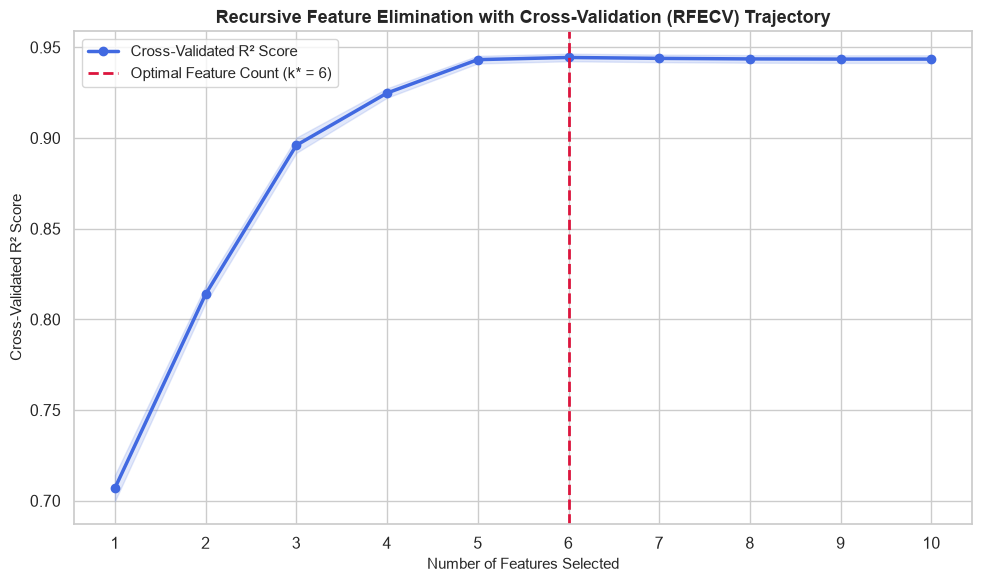

In [12]:
# Visualizing RFECV trajectory curve
fig, ax = plt.subplots(figsize=(10, 6))
num_feats = df_traj['Number_of_Features']
cv_scores = df_traj['Mean_CV_R2']
cv_stds = df_traj['Std_CV_R2']
opt_k = int(df_traj.loc[df_traj['Optimal_Selection'] == 'YES (Optimal)', 'Number_of_Features'].values[0])

ax.plot(num_feats, cv_scores, marker='o', linewidth=2.5, color='royalblue', label='Cross-Validated R² Score')
ax.fill_between(num_feats, cv_scores - cv_stds, cv_scores + cv_stds, alpha=0.15, color='royalblue')
ax.axvline(opt_k, color='crimson', linestyle='--', linewidth=2, label=f'Optimal Feature Count (k* = {opt_k})')
ax.set_title("Recursive Feature Elimination with Cross-Validation (RFECV) Trajectory", fontweight='bold', fontsize=13)
ax.set_xlabel("Number of Features Selected", fontsize=11)
ax.set_ylabel("Cross-Validated R² Score", fontsize=11)
ax.set_xticks(num_feats)
ax.legend(fontsize=11)
plt.tight_layout()
plt.savefig("rfecv_optimal_features_curve.png", dpi=300)
plt.show()


In [13]:
efficiency_df = pd.read_csv("model_efficiency_before_after_rfe.csv")
efficiency_df


,Model_Stage,Feature_Count,Features_Included,Test_R2,Test_RMSE,Test_MAE,Training_Time_Sec,Inference_Latency_ms_per_1k,Efficiency_Verdict
0,Full Model (All Candidate Features),10,All 10 features,0.9520,32.1512,25.3799,3.049,0.02,Baseline (Redundant noise features retained)
1,RFE-Optimized Model (Pruned Subset),6,"Length_of_Membership, Time_on_App, Avg_Session...",0.9532,31.7666,25.0748,2.168,0.02,"Optimized (4 features pruned, speed improved, ..."


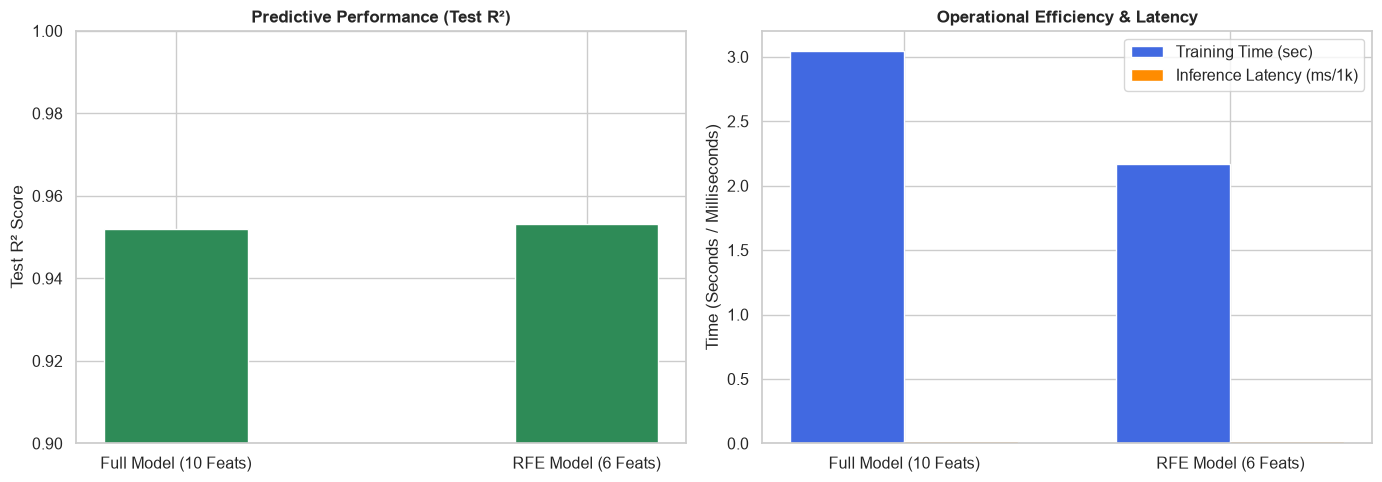

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

labels = ['Full Model (10 Feats)', f'RFE Model ({opt_k} Feats)']
r2_vals = [efficiency_df.loc[0, 'Test_R2'], efficiency_df.loc[1, 'Test_R2']]
tr_times = [efficiency_df.loc[0, 'Training_Time_Sec'], efficiency_df.loc[1, 'Training_Time_Sec']]
lat_times = [efficiency_df.loc[0, 'Inference_Latency_ms_per_1k'], efficiency_df.loc[1, 'Inference_Latency_ms_per_1k']]

x = np.arange(len(labels))
width = 0.35

axes[0].bar(x, r2_vals, width, color='seagreen')
axes[0].set_ylabel("Test R² Score")
axes[0].set_ylim([0.9, 1.0])
axes[0].set_xticks(x)
axes[0].set_xticklabels(labels)
axes[0].set_title("Predictive Performance (Test R²)", fontweight='bold')

axes[1].bar(x - width/2, tr_times, width, label='Training Time (sec)', color='royalblue')
axes[1].bar(x + width/2, lat_times, width, label='Inference Latency (ms/1k)', color='darkorange')
axes[1].set_xticks(x)
axes[1].set_xticklabels(labels)
axes[1].set_title("Operational Efficiency & Latency", fontweight='bold')
axes[1].set_ylabel("Time (Seconds / Milliseconds)")
axes[1].legend()

plt.tight_layout()
plt.savefig("model_efficiency_before_after_rfe.png", dpi=300)
plt.show()
